# Banking Intent Classifier

Predicts which of 77 banking intents a customer message belongs to, using the BANKING77 dataset.

## Contents

1. Problem definition
2. Setup
3. Load the data
4. Explore the data
5. Preprocess and split the data
6. Baseline model
7. Train DistilBERT
8. Train RoBERTa
9. Compare the models on the test set
10. Error analysis

## 1. Problem definition

### 1.1 The problem

Bank customers often contact support with short, free-text messages. Before a chatbot can help, it has to work out what the customer wants: its **intent**.

This project builds a classifier that takes one customer message and predicts one of 77 banking intents.

| Example customer message | Intent |
|---|---|
| "My card hasn't arrived yet" | `card_arrival` |
| "I think someone has been using my card" | `compromised_card` |
| "Why was I charged twice for the same purchase?" | `transaction_charged_twice` |

This is **single-label, multi-class text classification**.

### 1.2 Users and their needs

| User | Need |
|---|---|
| **Bank customers** | Reach the right help quickly, without repeating themselves or being sent to the wrong place |
| **Support teams** | Have routine requests handled automatically, and receive the cases that need a person |
| **Chatbot developers** | A model that is accurate, fast, and clear about when it is unsure |

### 1.3 Constraints and challenges

- **Many classes:** 77 intents is far harder than a typical sentiment task with two or three labels.
- **Very similar intents:** several intents share much of their vocabulary and differ only in meaning, as shown below.
- **Short messages:** a message gives little context, and the chatbot has no conversation history to draw on.
- **Limited data:** about 13,000 labelled messages across 77 intents, so each intent has relatively few examples.
- **Informal text:** real customers make typos and use casual wording.
- **Off-topic messages:** a real chatbot receives messages outside its 77 intents, but BANKING77 has no examples of these.
- **Response time:** a chatbot has to reply quickly, so model size and speed matter as well as accuracy.

| Similar intents | The difference |
|---|---|
| `lost_or_stolen_card` / `compromised_card` | The customer no longer has the card, or the card's details have been misused |
| `card_arrival` / `card_delivery_estimate` | An expected card is missing, or the customer wants to know how long delivery takes |
| `pending_transfer` / `transfer_not_received_by_recipient` | The transfer has not completed, or it appears sent but the recipient does not have it |

### 1.4 The cost of errors

Not all mistakes are equally serious, so overall accuracy alone is not enough.

| Severity | Example | Consequence |
|---|---|---|
| **High** | `lost_or_stolen_card` predicted as `card_not_working` | The card stays active while the customer gets troubleshooting steps, so there is a risk of financial loss |
| **Medium** | `transaction_charged_twice` predicted as `request_refund` | The customer gets the wrong process and has to contact support again |
| **Low** | `card_arrival` predicted as `card_delivery_estimate` | The answer is closely related, so it is a minor inconvenience |

For this reason, the system should say when it is unsure instead of always giving an answer, and the evaluation looks at results for each intent as well as overall scores.

### 1.5 Scope

**In scope**

- English messages about the 77 BANKING77 intents
- Predicting the most likely intents, with confidence scores
- Flagging messages that are off-topic or uncertain

**Out of scope**

- Carrying out actions, such as blocking a card or sending money
- Writing full chatbot replies
- Using conversation history
- Messages containing more than one request, since each example in the dataset has one label

This is a course project trained on a public dataset. It is not a production banking system.

### 1.6 Success criteria

These targets are set by this project, and later sections report whether each one was met.

| Requirement | Measure | Target |
|---|---|---|
| Correct classification | Macro F1 on the test set | At least 0.90 |
| Reported performance | Accuracy, precision, recall and F1 | All reported on the test set |
| Better than a simple approach | Macro F1 compared with the TF-IDF baseline | Higher than the baseline |
| Consistent across intents | Lowest-scoring intents | Identified and explained |
| Fast enough for a chatbot | Prediction time for one message on a CPU | Under 200 ms |
| Handles off-topic messages | Off-topic messages flagged, and banking messages wrongly flagged | At least 80% flagged, with under 10% wrongly flagged |
| Usable by a person | Working demo | A typed message returns the top intents with confidence scores |

## 2. Setup

Select a GPU first: **Runtime > Change runtime type > T4 GPU**. Then run these cells in order.

### 2.1 Install libraries

In [ ]:
%pip install -q transformers==5.21.0 datasets==4.8.5 evaluate==0.4.6 accelerate==1.15.0 scikit-learn==1.6.1 gradio==6.30.0

### 2.2 Record library versions

These versions are pinned in `requirements.txt` so that the notebook can be reproduced.

In [ ]:
import platform
from importlib.metadata import version

PACKAGES = [
    "transformers", "datasets", "evaluate", "accelerate", "torch",
    "scikit-learn", "pandas", "numpy", "matplotlib", "seaborn", "gradio",
]

print(f"# Python {platform.python_version()}")
for package in PACKAGES:
    print(f"{package}=={version(package)}")

# Python 3.13.16
transformers==5.21.0
datasets==4.8.5
evaluate==0.4.6
accelerate==1.15.0
torch==2.14.1+cu130
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
matplotlib==3.10.0
seaborn==0.13.2
gradio==6.30.0


### 2.3 Check the GPU

In [ ]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU found. Select Runtime > Change runtime type > T4 GPU, then run the notebook again."
    )

DEVICE = torch.device("cuda")
print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

GPU: Tesla T4
Memory: 15.6 GB


### 2.4 Connect Google Drive

Trained models are saved to Drive so that they survive Colab disconnects.

In [ ]:
from pathlib import Path

from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/banking-intent-classifier")
MODELS_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

for directory in (MODELS_DIR, RESULTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

test_file = PROJECT_DIR / "write_test.txt"
test_file.write_text("ok")
assert test_file.read_text() == "ok"
test_file.unlink()

print(f"Drive is ready: {PROJECT_DIR}")

Mounted at /content/drive
Drive is ready: /content/drive/MyDrive/banking-intent-classifier


### 2.5 Set the random seed

A fixed seed makes results repeatable.

In [ ]:
import random

import numpy as np

SEED = 42


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
print(f"Seed: {SEED}")

Seed: 42


## 3. Load the data

### 3.1 About the dataset

**BANKING77** (Casanueva et al., 2020, "Efficient Intent Detection with Dual Sentence Encoders") contains online banking queries, each labelled with one of 77 intents. It is released under the CC BY 4.0 license.

The files are loaded from the authors' repository, using a fixed commit so that the notebook always gets the same data.

In [ ]:
import json
from urllib.request import urlopen

import pandas as pd

BANKING77_COMMIT = "57ec275d8078af65b7731c2a98be812d844a6d6b"
BANKING77_URL = (
    "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/"
    f"{BANKING77_COMMIT}/banking_data"
)

# Two official intent names break the lowercase naming pattern.
LABEL_FIXES = {
    "Refund_not_showing_up": "refund_not_showing_up",
    "reverted_card_payment?": "reverted_card_payment",
}


def clean_labels(labels):
    return labels.replace(LABEL_FIXES)


def load_banking77():
    train = pd.read_csv(f"{BANKING77_URL}/train.csv")
    test = pd.read_csv(f"{BANKING77_URL}/test.csv")
    with urlopen(f"{BANKING77_URL}/categories.json") as response:
        categories = json.load(response)

    for split in (train, test):
        split["category"] = clean_labels(split["category"])

    intents = sorted(LABEL_FIXES.get(name, name) for name in categories)
    return train, test, intents


train_df, test_df, INTENTS = load_banking77()
print(f"Train messages: {len(train_df):,}")
print(f"Test messages: {len(test_df):,}")
print(f"Intents: {len(INTENTS)}")

Train messages: 10,003
Test messages: 3,080
Intents: 77


### 3.2 Map intents to numbers

Models work with numbers, so each intent gets a fixed ID. The IDs follow alphabetical order, so they are the same on every run.

In [ ]:
LABEL2ID = {intent: index for index, intent in enumerate(INTENTS)}
ID2LABEL = {index: intent for intent, index in LABEL2ID.items()}

for split in (train_df, test_df):
    split["label"] = split["category"].map(LABEL2ID)

print(f"First intent: {ID2LABEL[0]}")
print(f"Last intent: {ID2LABEL[len(INTENTS) - 1]}")

First intent: activate_my_card
Last intent: wrong_exchange_rate_for_cash_withdrawal


### 3.3 Check the data

These checks stop the notebook if the data is not what the rest of the project expects.

In [ ]:
EXPECTED_TRAIN_ROWS = 10_003
EXPECTED_TEST_ROWS = 3_080
EXPECTED_INTENTS = 77


def check_data(train, test, intents):
    assert len(train) == EXPECTED_TRAIN_ROWS, "Unexpected number of training rows"
    assert len(test) == EXPECTED_TEST_ROWS, "Unexpected number of test rows"
    assert len(intents) == len(set(intents)) == EXPECTED_INTENTS, "Unexpected intent list"

    for name, split in (("train", train), ("test", test)):
        assert split.notna().all().all(), f"Missing values in {name}"
        assert split["text"].str.strip().ne("").all(), f"Empty messages in {name}"
        assert set(split["category"]) == set(intents), f"Intents in {name} do not match the list"

    overlap = set(train["text"]) & set(test["text"])
    assert not overlap, f"{len(overlap)} messages appear in both train and test"


check_data(train_df, test_df, INTENTS)
print("All data checks passed")

All data checks passed


### 3.4 Preview the data

In [ ]:
train_df.sample(5, random_state=SEED)

,text,category,label
6883,Is it possible for me to change my PIN number?,change_pin,21
5836,I'm not sure why my card didn't work,declined_card_payment,25
8601,I don't think my top up worked,top_up_failed,59
2545,Can you explain why my payment was charged a fee?,card_payment_fee_charged,15
8697,How long does a transfer from a UK account tak...,balance_not_updated_after_bank_transfer,5


## 4. Explore the data

This section uses **only the training data**. The test set stays unseen until the final comparison, so that it gives a fair measure of performance.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

BAR_COLOR = "#2a78d6"
SURFACE_COLOR = "#fcfcfb"
TEXT_COLOR = "#0b0b0b"
MUTED_COLOR = "#52514e"
GRID_COLOR = "#e5e4e0"

plt.rcParams.update({
    "figure.facecolor": SURFACE_COLOR,
    "axes.facecolor": SURFACE_COLOR,
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": MUTED_COLOR,
    "axes.titlecolor": TEXT_COLOR,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID_COLOR,
    "text.color": TEXT_COLOR,
    "xtick.color": MUTED_COLOR,
    "ytick.color": MUTED_COLOR,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
})


def save_figure(figure, name):
    figure.savefig(RESULTS_DIR / f"{name}.png")

### 4.1 Intent balance

In [ ]:
intent_counts = train_df["category"].value_counts()

print(f"Fewest messages for an intent: {intent_counts.min()}")
print(f"Most messages for an intent: {intent_counts.max()}")
print(f"Median messages per intent: {intent_counts.median():.0f}")
print(f"Largest intent vs smallest: {intent_counts.max() / intent_counts.min():.1f} times")

Fewest messages for an intent: 35
Most messages for an intent: 187
Median messages per intent: 127
Largest intent vs smallest: 5.3 times


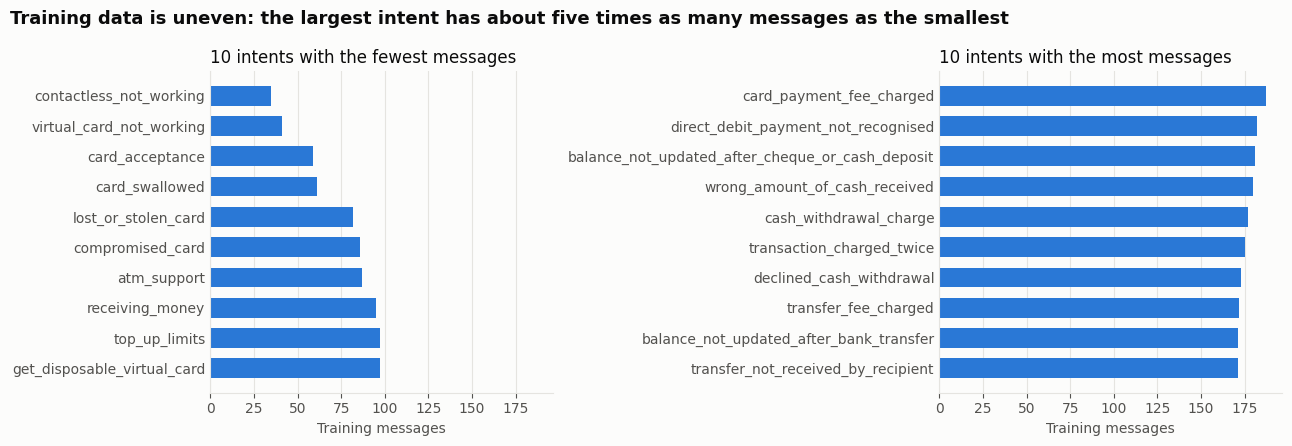

In [55]:
def plot_intent_balance(counts, top_n=10):
    figure, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
    panels = (
        (left, counts.tail(top_n), f"{top_n} intents with the fewest messages"),
        (right, counts.head(top_n).iloc[::-1], f"{top_n} intents with the most messages"),
    )
    for axis, values, title in panels:
        axis.barh(values.index, values.values, color=BAR_COLOR, height=0.65)
        axis.set_title(title)
        axis.set_xlabel("Training messages")
        axis.grid(axis="y", visible=False)
        axis.tick_params(axis="y", length=0)
    figure.suptitle(
        "Training data is uneven: the largest intent has about five times as many messages as the smallest",
        x=0.01, ha="left", fontsize=13, fontweight="bold",
    )
    figure.tight_layout()
    return figure


figure = plot_intent_balance(intent_counts)
save_figure(figure, "intent_balance")
plt.show()

**What this shows**

- The training data is uneven, from 35 messages (`contactless_not_working`) to 187 (`card_payment_fee_charged`).
- Three intents have fewer than 60 messages: `contactless_not_working`, `virtual_card_not_working` and `card_acceptance`. These may be harder to learn.
- Two of the high-risk intents are among the smallest: `lost_or_stolen_card` (82) and `compromised_card` (86). Scores for these need checking individually.
- The test set has exactly 40 messages per intent, so it does not share this imbalance.

**What this means for the project:** macro F1 is the main metric because it counts every intent equally. The validation split must be stratified, so that small intents keep their share.

### 4.2 Message length

In [56]:
word_counts = train_df["text"].str.split().str.len()

print(f"Median length: {word_counts.median():.0f} words")
print(f"95th percentile: {word_counts.quantile(0.95):.0f} words")
print(f"99th percentile: {word_counts.quantile(0.99):.0f} words")
print(f"Shortest: {word_counts.min()} words")
print(f"Longest: {word_counts.max()} words")

Median length: 10 words
95th percentile: 29 words
99th percentile: 43 words
Shortest: 2 words
Longest: 79 words


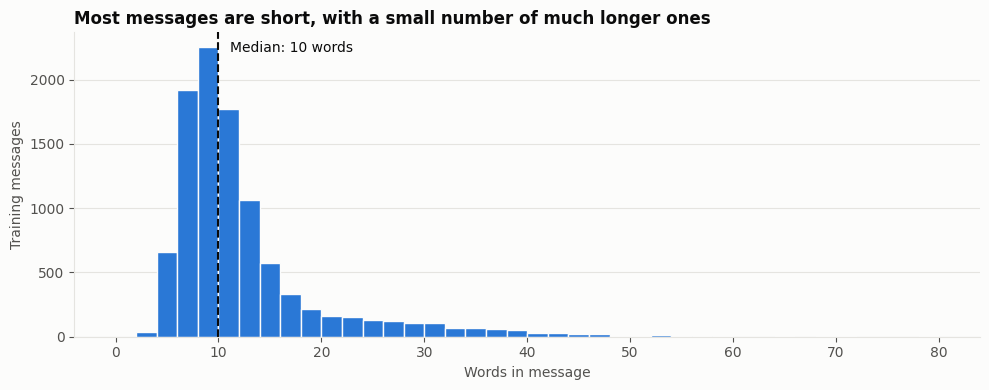

In [57]:
def plot_message_lengths(lengths):
    median = lengths.median()
    figure, axis = plt.subplots(figsize=(10, 4))
    axis.hist(lengths, bins=range(0, int(lengths.max()) + 3, 2), color=BAR_COLOR, edgecolor=SURFACE_COLOR)
    axis.axvline(median, color=TEXT_COLOR, linewidth=1.5, linestyle="--")
    axis.annotate(
        f"Median: {median:.0f} words",
        xy=(median, 1), xycoords=("data", "axes fraction"),
        xytext=(8, -14), textcoords="offset points", color=TEXT_COLOR,
    )
    axis.set_title("Most messages are short, with a small number of much longer ones", fontweight="bold")
    axis.set_xlabel("Words in message")
    axis.set_ylabel("Training messages")
    axis.grid(axis="x", visible=False)
    figure.tight_layout()
    return figure


figure = plot_message_lengths(word_counts)
save_figure(figure, "message_lengths")
plt.show()

**What this shows**

- Messages are short: half have 10 words or fewer, which confirms the limited context noted in section 1.3.
- A small group is much longer, with 42 messages over 50 words and a maximum of 79.

**What this means for the project:** the token limit is set in the next section using each model's own tokenizer. It needs to cover the long messages without wasting memory on padding.

### 4.3 Similar intents

Each intent is represented by the average TF-IDF vector of its messages. Cosine similarity between these vectors then shows which intents use the most similar wording.

In [58]:
from itertools import combinations

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def intent_similarity(data, intents):
    vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
    vectors = vectorizer.fit_transform(data["text"])
    centroids = np.vstack([
        np.asarray(vectors[(data["category"] == intent).to_numpy()].mean(axis=0))
        for intent in intents
    ])
    similarity = cosine_similarity(centroids)
    pairs = [
        (intents[a], intents[b], similarity[a, b])
        for a, b in combinations(range(len(intents)), 2)
    ]
    table = pd.DataFrame(pairs, columns=["intent_a", "intent_b", "similarity"])
    table = table.sort_values("similarity", ascending=False, ignore_index=True)
    table["rank"] = table.index + 1
    return table


similarity_table = intent_similarity(train_df, INTENTS)
print(f"Median similarity across all {len(similarity_table):,} pairs: {similarity_table['similarity'].median():.2f}")
similarity_table.head(10).round(2)

Median similarity across all 2,926 pairs: 0.13


,intent_a,intent_b,similarity,rank
0,card_payment_wrong_exchange_rate,wrong_exchange_rate_for_cash_withdrawal,0.81,1
1,top_up_failed,top_up_reverted,0.77,2
2,pending_top_up,top_up_failed,0.75,3
3,verify_my_identity,why_verify_identity,0.74,4
4,pending_top_up,top_up_reverted,0.72,5
5,getting_virtual_card,virtual_card_not_working,0.71,6
6,card_payment_fee_charged,transfer_fee_charged,0.67,7
7,declined_card_payment,reverted_card_payment,0.67,8
8,cash_withdrawal_charge,transfer_fee_charged,0.67,9
9,card_payment_fee_charged,cash_withdrawal_charge,0.67,10


The pairs highlighted as similar in section 1.3 can be checked the same way:

In [59]:
SECTION_1_PAIRS = [
    ("lost_or_stolen_card", "compromised_card"),
    ("card_arrival", "card_delivery_estimate"),
    ("pending_transfer", "transfer_not_received_by_recipient"),
]


def find_pair(table, first, second):
    match = table["intent_a"].eq(min(first, second)) & table["intent_b"].eq(max(first, second))
    return table[match]


pd.concat([find_pair(similarity_table, *pair) for pair in SECTION_1_PAIRS]).round(2)

,intent_a,intent_b,similarity,rank
61,compromised_card,lost_or_stolen_card,0.48,62
73,card_arrival,card_delivery_estimate,0.46,74
48,pending_transfer,transfer_not_received_by_recipient,0.50,49


**What this shows**

- The most similar pairs share their topic and differ in one detail, such as `top_up_failed` and `top_up_reverted`.
- The three pairs from section 1.3 rank between 49th and 74th of 2,926 pairs. Their similarity is well above the median of 0.13, but they are not the closest pairs.

**What this means for the project:** word overlap alone may not separate these intents, which supports using transformers that take context into account. This is only a prediction, because similar wording does not prove that a model will confuse two intents. The error analysis tests it against real mistakes.

### 4.4 Data quality

In [60]:
def normalize_text(text):
    words_only = text.str.lower().str.replace(r"[^\w\s]", "", regex=True)
    return words_only.str.split().str.join(" ")


def data_quality_report(data):
    normalized = normalize_text(data["text"])
    labels_per_text = data.groupby(normalized)["category"].nunique()
    return pd.Series({
        "Exact duplicates": data["text"].duplicated().sum(),
        "Duplicates after ignoring case and punctuation": normalized.duplicated().sum(),
        "Same text with different intents": (labels_per_text > 1).sum(),
        "Messages of two words or fewer": (data["text"].str.split().str.len() <= 2).sum(),
        "Messages containing digits": data["text"].str.contains(r"\d").sum(),
        "Messages containing a currency symbol": data["text"].str.contains("[£€$]").sum(),
        "Messages entirely in lowercase": (data["text"] == data["text"].str.lower()).sum(),
    }, name="Messages")


data_quality_report(train_df).to_frame()

,Messages
Exact duplicates,0
Duplicates after ignoring case and punctuation,12
Same text with different intents,0
Messages of two words or fewer,6
Messages containing digits,212
Messages containing a currency symbol,114
Messages entirely in lowercase,440


**What this shows**

- The data is clean: no exact duplicates, and no message appears with two different intents.
- 12 messages repeat another message once case and punctuation are ignored. All have matching labels, so they cannot cause conflicting training signals.
- Very short messages such as "Lost password" exist, and they have very little context.
- Digits and currency symbols appear in some messages and can carry meaning, such as amounts.

**What this means for the project:** cleaning should stay light, because transformers benefit from natural text. The 12 near-duplicates need handling before the validation split, so that no message appears on both sides.

### 4.5 Summary

| Finding | Decision |
|---|---|
| Uneven training data | Use macro F1 as the main metric, and stratify the validation split |
| Small high-risk intents | Report `lost_or_stolen_card` and `compromised_card` individually |
| Short messages, with a few long ones | Set the token limit from the tokenizers' own counts |
| Similar wording across intents | Test the prediction against real errors in the error analysis |
| Clean text, with meaningful digits and symbols | Keep cleaning light |
| 12 near-duplicates | Remove them before the validation split |

## 5. Preprocess and split the data

This section applies the decisions from the exploration: light cleaning, removing near-duplicates, a stratified validation split, and tokenizing the text for each model.

### 5.1 Clean the text

Cleaning only tidies whitespace, because some messages contain line breaks, double spaces or non-breaking spaces. Case, punctuation, digits and currency symbols all stay, because transformers can use them.

In [61]:
def clean_text(text):
    return text.str.split().str.join(" ")


for split in (train_df, test_df):
    changed = (clean_text(split["text"]) != split["text"]).sum()
    split["text"] = clean_text(split["text"])
    print(f"Messages with whitespace tidied: {changed}")

Messages with whitespace tidied: 466
Messages with whitespace tidied: 103


### 5.2 Remove near-duplicates from the training data

Two kinds of near-duplicate are removed, ignoring case and punctuation:

- **Repeats within the training data**, so that no message can end up in both the training and validation splits.
- **Copies of test messages**, because a model that has already seen a test message would get an unfairly easy question.

Only training rows are removed. The test set stays exactly as published, so the results can be compared with other work on BANKING77.

In [62]:
def remove_near_duplicates(train, test):
    train_keys = normalize_text(train["text"])
    test_keys = set(normalize_text(test["text"]))

    repeated = train_keys.duplicated()
    in_test = train_keys.isin(test_keys)

    print(f"Repeats within the training data: {repeated.sum()}")
    print(f"Copies of test messages: {in_test.sum()}")
    return train[~(repeated | in_test)].reset_index(drop=True)


unique_train_df = remove_near_duplicates(train_df, test_df)
print(f"Training messages kept: {len(unique_train_df):,} of {len(train_df):,}")

Repeats within the training data: 12
Copies of test messages: 11
Training messages kept: 9,980 of 10,003


### 5.3 Create the validation split

The validation split is used to tune the models and choose between them, so that the test set is only used once at the end. The split is **stratified**, which keeps each intent's share the same on both sides.

In [63]:
from sklearn.model_selection import train_test_split

VALIDATION_SIZE = 0.1

train_split, val_split = train_test_split(
    unique_train_df,
    test_size=VALIDATION_SIZE,
    stratify=unique_train_df["label"],
    random_state=SEED,
)
train_split = train_split.reset_index(drop=True)
val_split = val_split.reset_index(drop=True)

split_sizes = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "messages": [len(train_split), len(val_split), len(test_df)],
    "fewest_per_intent": [
        split["label"].value_counts().min() for split in (train_split, val_split, test_df)
    ],
    "most_per_intent": [
        split["label"].value_counts().max() for split in (train_split, val_split, test_df)
    ],
})
split_sizes

,split,messages,fewest_per_intent,most_per_intent
0,train,8982,32,168
1,validation,998,3,19
2,test,3080,40,40


These checks stop the notebook if any message appears in more than one split, or if an intent is missing.

In [64]:
def check_splits(train, val, test, intents):
    keys = {
        "train": set(normalize_text(train["text"])),
        "validation": set(normalize_text(val["text"])),
        "test": set(normalize_text(test["text"])),
    }
    for first, second in combinations(keys, 2):
        shared = keys[first] & keys[second]
        assert not shared, f"{len(shared)} messages appear in both {first} and {second}"

    for name, split in (("train", train), ("validation", val), ("test", test)):
        assert set(split["category"]) == set(intents), f"Intents missing from {name}"


check_splits(train_split, val_split, test_df, INTENTS)
print("All split checks passed")

All split checks passed


### 5.4 Choose the token limit

Models read tokens rather than words, and each model splits text differently, so lengths are measured with each model's own tokenizer on the training split.

In [65]:
from transformers import AutoTokenizer

MODEL_CHECKPOINTS = {
    "DistilBERT": "distilbert-base-uncased",
    "RoBERTa": "roberta-base",
}

tokenizers = {
    name: AutoTokenizer.from_pretrained(checkpoint)
    for name, checkpoint in MODEL_CHECKPOINTS.items()
}


def token_lengths(tokenizer, texts):
    return pd.Series([len(ids) for ids in tokenizer(texts.tolist())["input_ids"]])


length_summary = pd.DataFrame({
    name: token_lengths(tokenizer, train_split["text"]).describe(percentiles=[0.5, 0.99])
    for name, tokenizer in tokenizers.items()
}).loc[["50%", "99%", "max"]].round(0).astype(int)
length_summary

,DistilBERT,RoBERTa
50%,13,13
99%,53,51
max,98,93


The longest training message is under 100 tokens for both models, so a limit of **128** cuts off nothing in the training split. Each batch is later padded only to its own longest message, so short messages do not waste memory despite the higher limit.

In [66]:
MAX_LENGTH = 128

for name, tokenizer in tokenizers.items():
    longest = token_lengths(tokenizer, train_split["text"]).max()
    assert longest <= MAX_LENGTH, f"{name} would truncate training messages"

print(f"Token limit: {MAX_LENGTH}")

Token limit: 128


### 5.5 Tokenize the data

Each model gets its own tokenized copy of all three splits. The TF-IDF baseline does not use these, as it works directly from the cleaned text.

In [67]:
from datasets import Dataset, DatasetDict


def build_dataset(train, val, test):
    return DatasetDict({
        name: Dataset.from_pandas(split[["text", "label"]], preserve_index=False)
        for name, split in (("train", train), ("validation", val), ("test", test))
    })


def tokenize_dataset(dataset, tokenizer):
    def tokenize_batch(batch):
        return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

    return dataset.map(tokenize_batch, batched=True, remove_columns=["text"])


dataset = build_dataset(train_split, val_split, test_df)
tokenized_datasets = {
    name: tokenize_dataset(dataset, tokenizer)
    for name, tokenizer in tokenizers.items()
}
dataset

Map:   0%|          | 0/8982 [00:00<?, ? examples/s]

Map:   0%|          | 0/998 [00:00<?, ? examples/s]

Map:   0%|          | 0/3080 [00:00<?, ? examples/s]

Map:   0%|          | 0/8982 [00:00<?, ? examples/s]

Map:   0%|          | 0/998 [00:00<?, ? examples/s]

Map:   0%|          | 0/3080 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 8982
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 998
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 3080
    })
})

The same message looks different to each model:

In [68]:
EXAMPLE_MESSAGE = "Why was I charged £5 twice?"

for name, tokenizer in tokenizers.items():
    ids = tokenizer(EXAMPLE_MESSAGE)["input_ids"]
    print(f"{name}: {tokenizer.convert_ids_to_tokens(ids)}")

DistilBERT: ['[CLS]', 'why', 'was', 'i', 'charged', '£5', 'twice', '?', '[SEP]']
RoBERTa: ['<s>', 'Why', 'Ġwas', 'ĠI', 'Ġcharged', 'ĠÂ£', '5', 'Ġtwice', '?', '</s>']


**What this shows**

- DistilBERT lowercases everything, so "Why" and "why" are the same token to it.
- RoBERTa keeps capital letters, and marks the start of a new word with `Ġ`.

This is one reason for comparing the two models: they do not receive quite the same information.

## 6. Baseline model

A simple baseline shows how much the transformers actually add. If they cannot clearly beat it, their extra size and complexity are hard to justify.

The baseline has two parts:

- **TF-IDF** turns each message into a vector of word and phrase scores, with distinctive terms scoring higher.
- **Logistic regression** learns a weight for each term and each intent.

It treats a message as a bag of terms, so it has no real sense of word order or context beyond two-word phrases.

### 6.1 Scoring

The same scoring function is used for every model, so that the comparison is fair. Precision, recall and F1 are macro averages, which count every intent equally.

In [69]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


def compute_scores(true_labels, predicted_labels):
    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels, predicted_labels, average="macro", zero_division=0
    )
    return {
        "accuracy": accuracy_score(true_labels, predicted_labels),
        "precision": precision,
        "recall": recall,
        "macro_f1": f1,
    }

### 6.2 Tune the baseline

Each combination of settings is trained on the training split and scored on the validation split. The test set is not used.

| Setting | Options | What it controls |
|---|---|---|
| `ngram_range` | Single words, or words and two-word phrases | Whether phrases such as "top up" count as terms |
| `C` | 1, 10, 100 | How closely the model fits the training data, with higher values fitting more closely |
| `class_weight` | None, balanced | Whether errors on rare intents count for more during training |

In [70]:
from itertools import product

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

BASELINE_GRID = {
    "ngram_range": [(1, 1), (1, 2)],
    "C": [1, 10, 100],
    "class_weight": [None, "balanced"],
}


def build_baseline(ngram_range, C, class_weight):
    return make_pipeline(
        TfidfVectorizer(ngram_range=ngram_range, sublinear_tf=True),
        LogisticRegression(C=C, class_weight=class_weight, max_iter=2000, random_state=SEED),
    )


def tune_baseline(train, val, grid):
    results = []
    for values in product(*grid.values()):
        settings = dict(zip(grid, values))
        model = build_baseline(**settings)
        model.fit(train["text"], train["label"])
        scores = compute_scores(val["label"], model.predict(val["text"]))
        results.append({**settings, **scores})
    return pd.DataFrame(results).sort_values("macro_f1", ascending=False, ignore_index=True)


baseline_tuning = tune_baseline(train_split, val_split, BASELINE_GRID)
baseline_tuning.round(3)

,ngram_range,C,class_weight,accuracy,precision,recall,macro_f1
0,"(1, 1)",10,None,0.875,0.882,0.869,0.870
1,"(1, 1)",100,balanced,0.874,0.879,0.869,0.869
2,"(1, 2)",100,None,0.870,0.877,0.866,0.868
3,"(1, 2)",10,balanced,0.868,0.875,0.868,0.867
4,"(1, 1)",10,balanced,0.873,0.876,0.867,0.866
5,"(1, 1)",100,None,0.870,0.876,0.864,0.865
6,"(1, 2)",100,balanced,0.867,0.873,0.865,0.865
7,"(1, 2)",10,None,0.866,0.875,0.862,0.864
8,"(1, 2)",1,balanced,0.853,0.860,0.856,0.853
9,"(1, 1)",1,balanced,0.856,0.859,0.855,0.852


**What this shows**

- `C` matters most: every setting with `C` of 1 scores lowest.
- The top settings are very close, within about 0.01 macro F1. With 998 validation messages, differences this small may be noise, so the ranking near the top should not be over-interpreted.
- Two-word phrases and balanced class weights give no clear benefit here.

### 6.3 Train and save the best baseline

The best settings are chosen by validation macro F1. The model is trained on the training split only, which matches how the transformers will be trained.

In [71]:
import joblib

best_settings = baseline_tuning.loc[0, list(BASELINE_GRID)].to_dict()
print(f"Best settings: {best_settings}")

baseline_model = build_baseline(**best_settings)
baseline_model.fit(train_split["text"], train_split["label"])
joblib.dump(baseline_model, MODELS_DIR / "tfidf_baseline.joblib")

validation_scores = {
    "TF-IDF baseline": compute_scores(val_split["label"], baseline_model.predict(val_split["text"]))
}
pd.DataFrame(validation_scores).T.to_csv(RESULTS_DIR / "validation_scores.csv")
pd.DataFrame(validation_scores).T.round(3)

Best settings: {'ngram_range': (1, 1), 'C': 10, 'class_weight': None}


,accuracy,precision,recall,macro_f1
TF-IDF baseline,0.875,0.882,0.869,0.87


**What this shows**

- The baseline reaches a validation macro F1 of about 0.87. This is the score the transformers need to beat.
- It is already fairly strong for such a simple model, which suggests many intents have distinctive vocabulary.
- It falls short of the 0.90 target from section 1.6. That target applies to the final model, so this is not a failure of the baseline.

### 6.4 What the baseline learned

A benefit of this model is that its decisions can be inspected. These are the terms that most strongly point towards each of the similar high-risk intents.

In [72]:
def top_terms(model, intent, count=10):
    vectorizer, classifier = model.steps[0][1], model.steps[1][1]
    terms = vectorizer.get_feature_names_out()
    row = list(classifier.classes_).index(LABEL2ID[intent])
    strongest = np.argsort(classifier.coef_[row])[::-1][:count]
    return list(terms[strongest])


pd.DataFrame({
    intent: top_terms(baseline_model, intent)
    for intent in ("lost_or_stolen_card", "compromised_card")
})

,lost_or_stolen_card,compromised_card
0,stolen,someone
1,card,transactions
2,lost,fraud
3,missing,used
4,find,using
5,freeze,fraudulent
6,stole,replacement
7,my,think
8,took,stop
9,status,card


**What this shows**

- Many terms make sense, such as "stolen" and "lost" for `lost_or_stolen_card`, and "fraud" and "someone" for `compromised_card`.
- General words also carry weight, such as "my" and "card". The word "card" appears in both lists, so it does little to separate these intents.

**What this means for the project:** the model relies on individual words. A message that means "someone has my card" without using these words could be misclassified, which is where transformers should help. The test-set comparison and error analysis check whether they do.

## 7. Train DistilBERT

DistilBERT is a smaller, faster version of BERT. Unlike the baseline, it reads the whole message in order, so it can use context rather than individual words alone.

**Fine-tuning** starts from a model already trained on a large amount of general English text, and adapts it to banking intents. A new classification layer with 77 outputs is added on top.

Training code is shared with RoBERTa, so that both models get the same treatment and the comparison is fair.

### 7.1 Training settings

| Setting | Value | Why |
|---|---|---|
| Learning rates tried | 2e-5, 3e-5, 5e-5 | A common range for fine-tuning transformers, compared on the validation split |
| Maximum epochs | 10 | An upper limit, which early stopping can end sooner |
| Early stopping | After 2 epochs without improvement | Stops training before the model overfits |
| Batch size | 32 | Fits comfortably in GPU memory for short messages |
| Weight decay | 0.01 | A light penalty on large weights, which helps reduce overfitting |
| Warmup | 1 epoch | Raises the learning rate gradually, which helps early training stay stable |

Each model is saved to Google Drive once tuning finishes. When a saved model exists, the notebook loads it instead of training again, so that **Run all** does not repeat long training runs. Set `RETRAIN = True` to train again.

In [73]:
import shutil
import time

from transformers import (
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
)

LEARNING_RATES = [2e-5, 3e-5, 5e-5]
MAX_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 2
BATCH_SIZE = 32
EVAL_BATCH_SIZE = 64
WEIGHT_DECAY = 0.01
RETRAIN = False

CHECKPOINTS_DIR = Path("checkpoints")

### 7.2 Shared training code

DistilBERT's tokenized data includes a `token_type_ids` column that the model does not use. The `Trainer` removes columns a model does not accept, so this has no effect on training.

In [74]:
def trainer_metrics(prediction):
    logits, labels = prediction
    return compute_scores(labels, np.argmax(logits, axis=-1))


def build_training_args(output_dir, learning_rate, steps_per_epoch):
    return TrainingArguments(
        output_dir=str(output_dir),
        learning_rate=learning_rate,
        num_train_epochs=MAX_EPOCHS,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        weight_decay=WEIGHT_DECAY,
        warmup_steps=steps_per_epoch,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        fp16=torch.cuda.is_available(),
        seed=SEED,
        report_to="none",
    )


def train_once(checkpoint, tokenizer, tokenized, learning_rate, output_dir):
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint,
        num_labels=len(INTENTS),
        id2label=ID2LABEL,
        label2id=LABEL2ID,
    )
    steps_per_epoch = len(tokenized["train"]) // BATCH_SIZE
    trainer = Trainer(
        model=model,
        args=build_training_args(output_dir, learning_rate, steps_per_epoch),
        train_dataset=tokenized["train"],
        eval_dataset=tokenized["validation"],
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=trainer_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOPPING_PATIENCE)],
    )
    start = time.time()
    trainer.train()
    return trainer, time.time() - start


def epoch_history(trainer, learning_rate):
    logs = trainer.state.log_history
    train_loss = {row["epoch"]: row["loss"] for row in logs if "loss" in row}
    return pd.DataFrame([
        {
            "learning_rate": learning_rate,
            "epoch": row["epoch"],
            "train_loss": train_loss.get(row["epoch"]),
            "val_loss": row["eval_loss"],
            "val_macro_f1": row["eval_macro_f1"],
        }
        for row in logs if "eval_macro_f1" in row
    ])


def tune_transformer(name, checkpoint, tokenizer, tokenized, learning_rates):
    model_dir = MODELS_DIR / name.lower()
    tuning_path = RESULTS_DIR / f"{name.lower()}_tuning.csv"
    history_path = RESULTS_DIR / f"{name.lower()}_history.csv"

    if tuning_path.exists() and history_path.exists() and model_dir.exists() and not RETRAIN:
        print(f"Loading saved {name} results. Set RETRAIN = True to train again.")
        return pd.read_csv(tuning_path), pd.read_csv(history_path)

    tuning_rows = []
    histories = []
    best_f1 = -1.0
    for learning_rate in learning_rates:
        output_dir = CHECKPOINTS_DIR / f"{name.lower()}_{learning_rate}"
        trainer, seconds = train_once(checkpoint, tokenizer, tokenized, learning_rate, output_dir)
        history = epoch_history(trainer, learning_rate)
        histories.append(history)

        macro_f1 = history["val_macro_f1"].max()
        tuning_rows.append({
            "learning_rate": learning_rate,
            "best_val_macro_f1": macro_f1,
            "best_epoch": history.loc[history["val_macro_f1"].idxmax(), "epoch"],
            "epochs_run": history["epoch"].max(),
            "train_minutes": seconds / 60,
        })
        print(f"{name} at learning rate {learning_rate}: macro F1 {macro_f1:.3f} in {seconds / 60:.1f} minutes")

        if macro_f1 > best_f1:
            best_f1 = macro_f1
            trainer.save_model(model_dir)
            tokenizer.save_pretrained(model_dir)

        del trainer
        torch.cuda.empty_cache()
        shutil.rmtree(output_dir, ignore_errors=True)

    tuning = pd.DataFrame(tuning_rows).sort_values("best_val_macro_f1", ascending=False, ignore_index=True)
    history = pd.concat(histories, ignore_index=True)
    tuning.to_csv(tuning_path, index=False)
    history.to_csv(history_path, index=False)
    return tuning, history


def predict_labels(model_dir, tokenizer, data):
    model = AutoModelForSequenceClassification.from_pretrained(model_dir)
    trainer = Trainer(
        model=model,
        args=TrainingArguments(
            output_dir=str(CHECKPOINTS_DIR / "predict"),
            per_device_eval_batch_size=EVAL_BATCH_SIZE,
            report_to="none",
        ),
        data_collator=DataCollatorWithPadding(tokenizer),
    )
    return np.argmax(trainer.predict(data).predictions, axis=-1)


def plot_learning_curves(history, name, baseline_f1):
    colors = ["#2a78d6", "#eb6834", "#1baf7a"]
    figure, axis = plt.subplots(figsize=(10, 4.5))
    for color, (learning_rate, runs) in zip(colors, history.groupby("learning_rate")):
        axis.plot(
            runs["epoch"], runs["val_macro_f1"],
            color=color, linewidth=2, marker="o", markersize=7,
            label=f"Learning rate {learning_rate:g}",
        )
    axis.axhline(baseline_f1, color=MUTED_COLOR, linewidth=1.5, linestyle="--")
    axis.annotate(
        f"TF-IDF baseline: {baseline_f1:.3f}",
        xy=(1, baseline_f1), xycoords=("axes fraction", "data"),
        xytext=(-4, -14), textcoords="offset points", ha="right", color=MUTED_COLOR,
    )
    axis.set_title(f"{name} validation macro F1 by epoch", fontweight="bold")
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Validation macro F1")
    axis.xaxis.get_major_locator().set_params(integer=True)
    axis.grid(axis="x", visible=False)
    axis.legend(frameon=False, loc="lower right")
    figure.tight_layout()
    return figure

### 7.3 Train and tune DistilBERT

This is the slowest cell so far, because it trains one model for each learning rate. Keep the Colab tab open while it runs.

In [75]:
distilbert_tuning, distilbert_history = tune_transformer(
    "DistilBERT",
    MODEL_CHECKPOINTS["DistilBERT"],
    tokenizers["DistilBERT"],
    tokenized_datasets["DistilBERT"],
    LEARNING_RATES,
)
distilbert_tuning.round({"best_val_macro_f1": 3, "train_minutes": 1})

Loading saved DistilBERT results. Set RETRAIN = True to train again.


,learning_rate,best_val_macro_f1,best_epoch,epochs_run,train_minutes
0,0.00005,0.921,9.0,10.0,5.4
1,0.00003,0.914,9.0,10.0,4.0
2,0.00002,0.911,8.0,10.0,4.8


### 7.4 Learning curves

These curves show how validation macro F1 changes during training, compared with the baseline.

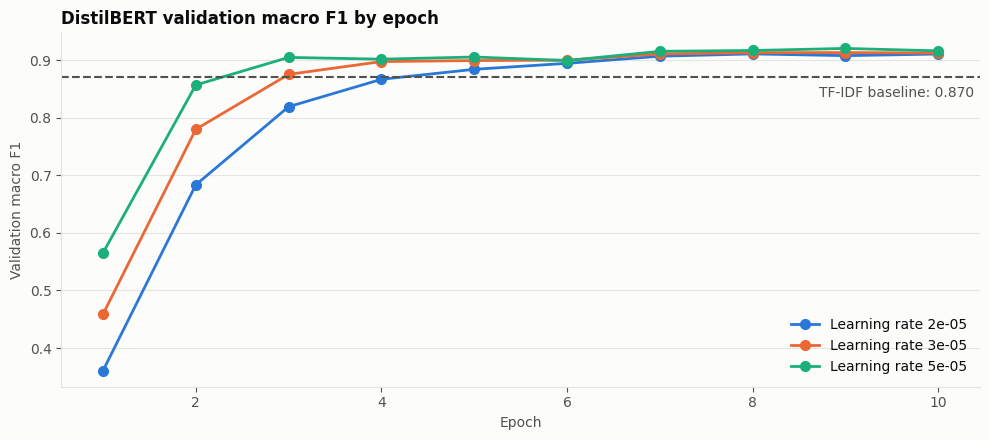

In [76]:
figure = plot_learning_curves(
    distilbert_history, "DistilBERT", validation_scores["TF-IDF baseline"]["macro_f1"]
)
save_figure(figure, "distilbert_learning_curves")
plt.show()

**What this shows**

- All three learning rates pass the baseline, and they finish close together. Higher learning rates get there sooner.
- Validation macro F1 flattens out after about epoch 7, so further training would be unlikely to help much.
- All three runs used the full 10 epochs. The scores moved up and down enough that early stopping never triggered.
- By the final epochs the training loss is close to zero, while validation loss stopped improving by about epoch 5 at the highest learning rate. The model is fitting the training data much more closely than new messages, which is a sign of overfitting, although validation macro F1 did not fall.

### 7.5 Score the saved model

The saved model is loaded back from Google Drive and scored, which confirms that the saved copy works. The test set is still not used.

In [77]:
def add_validation_scores(name):
    predictions = predict_labels(
        MODELS_DIR / name.lower(), tokenizers[name], tokenized_datasets[name]["validation"]
    )
    validation_scores[name] = compute_scores(val_split["label"], predictions)
    table = pd.DataFrame(validation_scores).T
    table.to_csv(RESULTS_DIR / "validation_scores.csv")
    return table.round(3)


add_validation_scores("DistilBERT")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,accuracy,precision,recall,macro_f1
TF-IDF baseline,0.875,0.882,0.869,0.870
DistilBERT,0.923,0.927,0.919,0.921


**What this shows**

- DistilBERT reaches a validation macro F1 of about 0.92, compared with about 0.87 for the baseline. That is roughly 48 more correct answers out of 998 validation messages.
- It passes the 0.90 target from section 1.6 on validation data. The official result comes later, from the test set.
- The best learning rate was 5e-5, at epoch 9. It is the highest rate tried, so a higher one could be slightly better.
- The learning rates differ by about 0.01 macro F1. Each was trained once on 998 validation messages, so this ranking may be partly chance.
- This score is likely to be slightly optimistic, because the validation split was also used to pick the learning rate and the epoch.

## 8. Train RoBERTa

RoBERTa is a larger model than DistilBERT, with more layers and more parameters. It was trained on more data and with an improved pretraining procedure than the original BERT, and it keeps capital letters in its input.

| | DistilBERT | RoBERTa |
|---|---|---|
| **Layers** | 6 | 12 |
| **Size** | About 257 MB | About 480 MB |
| **Capital letters** | Removed | Kept |

The question for this section is whether the extra size is worth it. RoBERTa uses the same training code, settings and learning rates as DistilBERT, so that the comparison is fair.

### 8.1 Train and tune RoBERTa

This cell trains one model for each learning rate, and takes longer than DistilBERT did. Keep the Colab tab open while it runs. Results are saved to Google Drive once all three runs finish.

In [78]:
roberta_tuning, roberta_history = tune_transformer(
    "RoBERTa",
    MODEL_CHECKPOINTS["RoBERTa"],
    tokenizers["RoBERTa"],
    tokenized_datasets["RoBERTa"],
    LEARNING_RATES,
)
roberta_tuning.round({"best_val_macro_f1": 3, "train_minutes": 1})

Loading saved RoBERTa results. Set RETRAIN = True to train again.


,learning_rate,best_val_macro_f1,best_epoch,epochs_run,train_minutes
0,0.00005,0.934,8.0,10.0,12.2
1,0.00003,0.930,6.0,8.0,8.3
2,0.00002,0.924,7.0,9.0,9.5


### 8.2 Learning curves

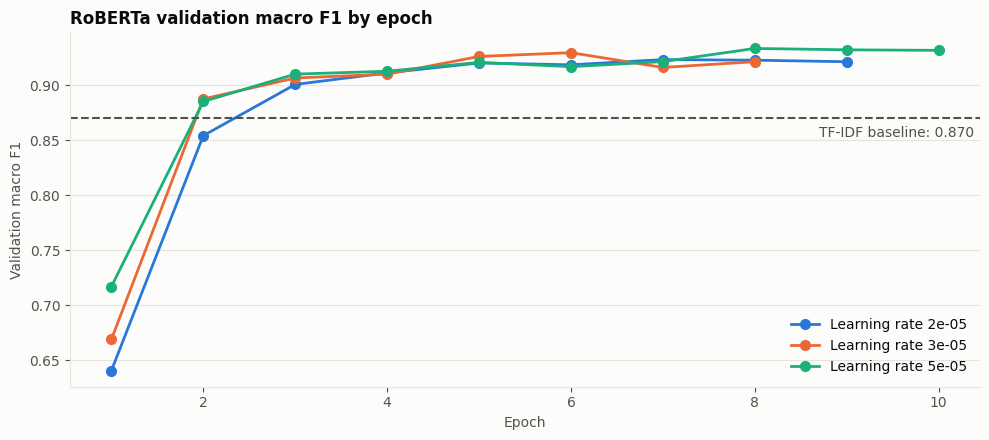

In [79]:
figure = plot_learning_curves(
    roberta_history, "RoBERTa", validation_scores["TF-IDF baseline"]["macro_f1"]
)
save_figure(figure, "roberta_learning_curves")
plt.show()

**What this shows**

- All three learning rates pass the baseline by epoch 3, and stay close together after that.
- Early stopping ended two of the runs early: 3e-5 after 8 epochs and 2e-5 after 9. Only 5e-5 used all 10 epochs.
- Validation macro F1 levels off at about 0.92 to 0.93 from around epoch 5.

### 8.3 Score the saved model

The saved model is loaded back from Google Drive and scored on the validation split. The test set is still not used.

In [80]:
add_validation_scores("RoBERTa")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,accuracy,precision,recall,macro_f1
TF-IDF baseline,0.875,0.882,0.869,0.870
DistilBERT,0.923,0.927,0.919,0.921
RoBERTa,0.934,0.938,0.934,0.934


**What this shows**

| Model | Validation macro F1 | Training time for all three learning rates |
|---|---|---|
| TF-IDF baseline | 0.870 | A few minutes, without a GPU |
| DistilBERT | 0.921 | About 14 minutes |
| RoBERTa | 0.934 | About 30 minutes |

- RoBERTa has the highest validation macro F1, at about 0.934. That is roughly 11 more correct answers than DistilBERT, and about 59 more than the baseline, out of 998 validation messages.
- The gain over DistilBERT is small. Each model was trained once per learning rate and scored on 998 messages, so this gap may be partly chance.
- RoBERTa costs about twice as much: roughly twice the training time and almost twice the size, at about 480 MB.
- As with DistilBERT, the best learning rate was 5e-5, the highest one tried.
- These scores are likely to be slightly optimistic, because the validation split also chose the learning rate and epoch. The test set gives the fair comparison in the next section, using 3,080 messages that no model has seen.

## 9. Compare the models on the test set

This is the first time any model sees the test set. All settings were already chosen using the validation split, so these scores are a fair measure of how each model handles messages it has never seen.

The test set has 3,080 messages, with exactly 40 for each intent. It is larger and more balanced than the validation split, so it gives a more reliable comparison.

### 9.1 Test scores

In [81]:
MODEL_NAMES = ["TF-IDF baseline", "DistilBERT", "RoBERTa"]


def predict_test(name):
    if name == "TF-IDF baseline":
        return np.asarray(baseline_model.predict(test_df["text"]))
    return predict_labels(MODELS_DIR / name.lower(), tokenizers[name], tokenized_datasets[name]["test"])


test_labels = test_df["label"].to_numpy()
test_predictions = {name: predict_test(name) for name in MODEL_NAMES}

test_scores = pd.DataFrame({
    name: compute_scores(test_labels, predictions)
    for name, predictions in test_predictions.items()
}).T
test_scores.to_csv(RESULTS_DIR / "test_scores.csv")

prediction_table = test_df[["text", "category"]].assign(**{
    name: [ID2LABEL[label] for label in predictions]
    for name, predictions in test_predictions.items()
})
prediction_table.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)

test_scores.round(3)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,accuracy,precision,recall,macro_f1
TF-IDF baseline,0.897,0.902,0.897,0.898
DistilBERT,0.929,0.932,0.929,0.929
RoBERTa,0.931,0.934,0.931,0.931


**What this shows**

- Both transformers pass the 0.90 macro F1 target from section 1.6: DistilBERT scores about 0.929 and RoBERTa about 0.931.
- The baseline scores about 0.898, just below the target.
- Both transformers answer roughly 100 more of the 3,080 test messages correctly than the baseline.

### 9.2 Validation compared with test

The validation scores were used to choose settings, so they may be slightly optimistic. A large drop on the test set would suggest overfitting to the validation split.

In [82]:
score_comparison = pd.DataFrame({
    "validation_macro_f1": pd.DataFrame(validation_scores).T["macro_f1"],
    "test_macro_f1": test_scores["macro_f1"],
})
score_comparison["difference"] = score_comparison["test_macro_f1"] - score_comparison["validation_macro_f1"]
score_comparison.round(3)

,validation_macro_f1,test_macro_f1,difference
TF-IDF baseline,0.870,0.898,0.027
DistilBERT,0.921,0.929,0.008
RoBERTa,0.934,0.931,-0.002


**What this shows**

- There is no sign of overfitting to the validation split. Test scores are within about 0.01 of validation scores for both transformers.
- RoBERTa's lead over DistilBERT shrank from about 0.013 on validation to about 0.003 on the test set. The test set is larger and was never used for choices, so its smaller gap is the more reliable one.
- The baseline and DistilBERT score slightly higher on test than on validation. The test set has 40 messages for every intent, so rare intents carry more weight in it than in the validation split.

### 9.3 How certain are the differences?

A single score does not show how much it depends on which messages happened to be in the test set. **Bootstrapping** estimates this: it builds 1,000 new test sets by sampling messages with replacement, and scores every model on each one.

- The **95% interval** is the range covering the middle 95% of those scores.
- For each pair of models, the same samples are used for both, so the comparison is paired. If one model wins in nearly every sample, its lead is unlikely to be chance.

In [83]:
from sklearn.metrics import f1_score

BOOTSTRAP_SAMPLES = 1000


def bootstrap_macro_f1(true_labels, predictions, samples=BOOTSTRAP_SAMPLES):
    rng = np.random.default_rng(SEED)
    indices = rng.integers(0, len(true_labels), size=(samples, len(true_labels)))
    return {
        name: np.array([
            f1_score(true_labels[rows], predicted[rows], average="macro", zero_division=0)
            for rows in indices
        ])
        for name, predicted in predictions.items()
    }


bootstrap_scores = bootstrap_macro_f1(test_labels, test_predictions)

intervals = pd.DataFrame({
    name: {
        "macro_f1": test_scores.loc[name, "macro_f1"],
        "interval_low": np.percentile(scores, 2.5),
        "interval_high": np.percentile(scores, 97.5),
    }
    for name, scores in bootstrap_scores.items()
}).T
intervals.round(3)

,macro_f1,interval_low,interval_high
TF-IDF baseline,0.898,0.887,0.907
DistilBERT,0.929,0.919,0.937
RoBERTa,0.931,0.921,0.940


In [84]:
MODEL_PAIRS = [
    ("DistilBERT", "TF-IDF baseline"),
    ("RoBERTa", "TF-IDF baseline"),
    ("RoBERTa", "DistilBERT"),
]

pair_rows = []
for better, other in MODEL_PAIRS:
    difference = bootstrap_scores[better] - bootstrap_scores[other]
    pair_rows.append({
        "comparison": f"{better} minus {other}",
        "macro_f1_difference": test_scores.loc[better, "macro_f1"] - test_scores.loc[other, "macro_f1"],
        "interval_low": np.percentile(difference, 2.5),
        "interval_high": np.percentile(difference, 97.5),
        "share_of_samples_ahead": (difference > 0).mean(),
    })

pair_differences = pd.DataFrame(pair_rows).set_index("comparison")
pair_differences.to_csv(RESULTS_DIR / "test_pair_differences.csv")
pair_differences.round(3)

,macro_f1_difference,interval_low,interval_high,share_of_samples_ahead
comparison,,,,
DistilBERT minus TF-IDF baseline,0.031,0.023,0.041,1.00
RoBERTa minus TF-IDF baseline,0.034,0.024,0.044,1.00
RoBERTa minus DistilBERT,0.003,-0.005,0.010,0.74


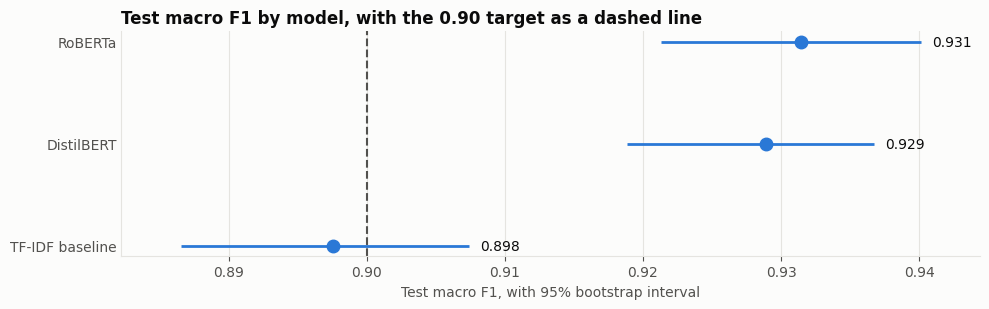

In [85]:
TARGET_MACRO_F1 = 0.90


def plot_test_scores(intervals, target):
    ordered = intervals.sort_values("macro_f1")
    positions = np.arange(len(ordered))
    figure, axis = plt.subplots(figsize=(10, 3.2))
    axis.hlines(positions, ordered["interval_low"], ordered["interval_high"], color=BAR_COLOR, linewidth=2)
    axis.plot(ordered["macro_f1"], positions, "o", color=BAR_COLOR, markersize=9)
    for position, (low, high, score) in enumerate(ordered[["interval_low", "interval_high", "macro_f1"]].to_numpy()):
        axis.annotate(f"{score:.3f}", xy=(high, position), xytext=(8, 0), textcoords="offset points", va="center", color=TEXT_COLOR)
    axis.axvline(target, color=MUTED_COLOR, linewidth=1.5, linestyle="--")
    axis.set_yticks(positions, ordered.index)
    axis.set_xlabel("Test macro F1, with 95% bootstrap interval")
    axis.set_title(f"Test macro F1 by model, with the {target:.2f} target as a dashed line", fontweight="bold")
    axis.grid(axis="y", visible=False)
    axis.tick_params(axis="y", length=0)
    axis.margins(x=0.08)
    figure.tight_layout()
    return figure


figure = plot_test_scores(intervals, TARGET_MACRO_F1)
save_figure(figure, "test_scores")
plt.show()

**What this shows**

- **Both transformers beat the baseline**, and this is very unlikely to be chance: each was ahead in all 1,000 samples, and the whole interval for each difference is above zero.
- **RoBERTa and DistilBERT perform about the same.** RoBERTa was ahead in only 74% of samples, and the interval for the difference runs from about -0.005 to 0.010, which includes zero.
- **Both transformers meet the target with room to spare**: the lower end of each interval is about 0.92.

**What this means for the project:** RoBERTa is about twice the size and took about twice as long to train, without a clear gain in accuracy. DistilBERT is therefore the practical choice for a chatbot. The speed tests in the bonus work check how much faster it is.

### 9.4 High-risk intents

Section 1.4 identified mistakes on lost, stolen or misused cards as the most serious. For these intents, **recall** matters most: it is the share of real reports the model catches. A missed report could leave a card active.

In [86]:
HIGH_RISK_INTENTS = ["lost_or_stolen_card", "compromised_card"]


def per_intent_scores(true_labels, predicted_labels):
    precision, recall, f1, support = precision_recall_fscore_support(
        true_labels, predicted_labels, labels=list(range(len(INTENTS))), zero_division=0
    )
    return pd.DataFrame(
        {"precision": precision, "recall": recall, "f1": f1, "support": support},
        index=INTENTS,
    )


per_intent_test = {
    name: per_intent_scores(test_labels, predictions)
    for name, predictions in test_predictions.items()
}
pd.concat(
    {name: scores.loc[HIGH_RISK_INTENTS, ["precision", "recall", "f1"]] for name, scores in per_intent_test.items()}
).round(3)

precision  recall     f1
TF-IDF baseline lost_or_stolen_card      0.881   0.925  0.902
                compromised_card         0.923   0.900  0.911
DistilBERT      lost_or_stolen_card      0.854   0.875  0.864
                compromised_card         0.902   0.925  0.914
RoBERTa         lost_or_stolen_card      0.860   0.925  0.892
                compromised_card         0.944   0.850  0.895

**What this shows**

The transformers' overall advantage does **not** show up on these two intents.

| Model | `lost_or_stolen_card` reports missed | `compromised_card` reports missed |
|---|---|---|
| TF-IDF baseline | 3 of 40 | 4 of 40 |
| DistilBERT | 5 of 40 | 3 of 40 |
| RoBERTa | 3 of 40 | 6 of 40 |

- Every model misses between 3 and 6 real reports out of 40 for each intent.
- With only 40 messages per intent, each message moves recall by 0.025, so the differences between models here are too small to rank them.
- For a real bank, missing even a few of these reports is a serious problem. This is a limitation of all three models, and a reason for the chatbot to ask when it is unsure rather than always answering.

**What this means for the project:** the error analysis looks at which intents these messages were confused with, and why.

## 10. Error analysis

Scores show how often a model is wrong, but not why. This section looks at the mistakes themselves, using the test predictions from the previous section.

It focuses on **DistilBERT**, the practical choice from the test comparison, and compares it with the other models where that helps.

In [87]:
FOCUS_MODEL = "DistilBERT"

focus_predictions = test_predictions[FOCUS_MODEL]
focus_errors = focus_predictions != test_labels
print(f"{FOCUS_MODEL} errors: {focus_errors.sum()} of {len(test_labels):,} test messages")

DistilBERT errors: 219 of 3,080 test messages


### 10.1 Weakest intents

These are the intents where DistilBERT has the lowest F1, with the other models' scores for comparison. Each intent has 40 test messages, so one extra mistake changes recall by 0.025.

In [88]:
weakest_intents = pd.DataFrame({
    name: per_intent_test[name]["f1"] for name in MODEL_NAMES
}).sort_values(FOCUS_MODEL).head(10)
weakest_intents.round(3)

,TF-IDF baseline,DistilBERT,RoBERTa
balance_not_updated_after_bank_transfer,0.707,0.800,0.716
declined_transfer,0.880,0.800,0.873
pending_transfer,0.810,0.816,0.872
topping_up_by_card,0.825,0.846,0.795
failed_transfer,0.819,0.850,0.860
top_up_reverted,0.795,0.854,0.868
transfer_not_received_by_recipient,0.825,0.860,0.889
top_up_failed,0.790,0.861,0.878
declined_card_payment,0.848,0.864,0.938
lost_or_stolen_card,0.902,0.864,0.892


**What this shows**

- Eight of the ten weakest intents are about transfers or top-ups, such as `pending_transfer`, `failed_transfer` and `top_up_reverted`. These intents describe closely related situations, often in similar words.
- `lost_or_stolen_card` is among DistilBERT's ten weakest intents, which matches the high-risk results in section 9.4.
- No model is best on every weak intent. For example, the baseline scores highest on `declined_transfer` and `lost_or_stolen_card`.

### 10.2 Most confused pairs

Each row counts how often messages of one intent were predicted as another. The similarity rank comes from section 4.3, where 1 is the pair with the most similar wording out of 2,926. This tests the prediction made there: that similar wording leads to confusion.

In [89]:
def confused_pairs(true_labels, predicted_labels, top=10):
    mistakes = pd.DataFrame({"true": true_labels, "predicted": predicted_labels})
    mistakes = mistakes[mistakes["true"] != mistakes["predicted"]]
    counts = mistakes.value_counts().head(top).reset_index(name="count")
    counts["true_intent"] = counts["true"].map(ID2LABEL)
    counts["predicted_intent"] = counts["predicted"].map(ID2LABEL)
    counts["similarity_rank"] = [
        find_pair(similarity_table, a, b)["rank"].iloc[0]
        for a, b in zip(counts["true_intent"], counts["predicted_intent"])
    ]
    return counts[["true_intent", "predicted_intent", "count", "similarity_rank"]]


top_confusions = confused_pairs(test_labels, focus_predictions)
top_confusions.to_csv(RESULTS_DIR / "top_confusions.csv", index=False)
top_confusions

,true_intent,predicted_intent,count,similarity_rank
0,card_delivery_estimate,card_arrival,4,74
1,declined_transfer,declined_card_payment,4,72
2,why_verify_identity,verify_my_identity,4,4
3,pin_blocked,change_pin,4,40
4,top_up_by_bank_transfer_charge,transfer_fee_charged,4,100
5,transfer_timing,balance_not_updated_after_bank_transfer,4,30
6,fiat_currency_support,exchange_via_app,4,166
7,pending_transfer,balance_not_updated_after_bank_transfer,4,37
8,card_arrival,card_delivery_estimate,3,74
9,balance_not_updated_after_bank_transfer,transfer_not_received_by_recipient,3,20


In [90]:
SIMILAR_RANK_CUTOFF = 100

share_similar = (top_confusions["similarity_rank"] <= SIMILAR_RANK_CUTOFF).mean()
print(
    f"{share_similar:.0%} of the top confused pairs are among the {SIMILAR_RANK_CUTOFF} most similar pairs "
    f"(the top {SIMILAR_RANK_CUTOFF / len(similarity_table):.0%} of all pairs)"
)

90% of the top confused pairs are among the 100 most similar pairs (the top 3% of all pairs)


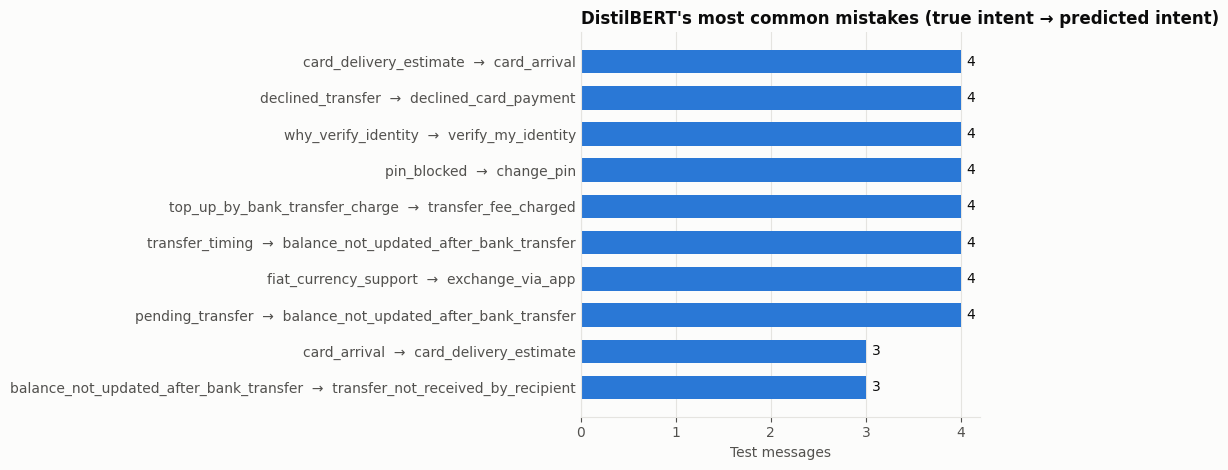

In [91]:
def plot_top_confusions(confusions):
    labels = [f"{a}  \u2192  {b}" for a, b in zip(confusions["true_intent"], confusions["predicted_intent"])]
    figure, axis = plt.subplots(figsize=(12, 5))
    axis.barh(labels[::-1], confusions["count"][::-1], color=BAR_COLOR, height=0.65)
    for position, count in enumerate(confusions["count"][::-1]):
        axis.annotate(str(count), xy=(count, position), xytext=(4, 0), textcoords="offset points", va="center", color=TEXT_COLOR)
    axis.set_title(f"{FOCUS_MODEL}'s most common mistakes", fontweight="bold")
    axis.set_xlabel("Test messages, shown as true intent \u2192 predicted intent")
    axis.grid(axis="y", visible=False)
    axis.tick_params(axis="y", length=0)
    axis.xaxis.get_major_locator().set_params(integer=True)
    figure.tight_layout()
    return figure


figure = plot_top_confusions(top_confusions)
save_figure(figure, "top_confusions")
plt.show()

**What this shows**

- **The prediction from section 4.3 holds.** Nine of DistilBERT's ten most confused pairs are among the 100 most similar pairs by wording, out of 2,926.
- No single confusion dominates. The most common mistakes happen only 3 or 4 times each, so DistilBERT's 219 errors are spread across many pairs.
- Some confusions go both ways, such as `card_arrival` and `card_delivery_estimate`. The model finds it hard to tell these apart in either direction.

### 10.3 High-risk misses

Every test message about a lost, stolen or misused card that DistilBERT got wrong, with what each model predicted.

In [92]:
high_risk_ids = [LABEL2ID[intent] for intent in HIGH_RISK_INTENTS]
missed_high_risk = np.isin(test_labels, high_risk_ids) & focus_errors

pd.set_option("display.max_colwidth", 120)
prediction_table[missed_high_risk]

,text,category,TF-IDF baseline,DistilBERT,RoBERTa
440,"My entire gym bag, including my wallet, was stolen out of my locker today. Everything in my wallet is gone - how do ...",lost_or_stolen_card,lost_or_stolen_card,top_up_reverted,lost_or_stolen_card
453,Is a copy of the police report necessary for completing the report process?,lost_or_stolen_card,lost_or_stolen_card,edit_personal_details,order_physical_card
454,I lost my wallet today with all my credit cards. Will you please block the card and send a replacement?,lost_or_stolen_card,lost_or_stolen_card,compromised_card,lost_or_stolen_card
461,"Someone stole my wallet earlier today, not sure exactly when, probably on Piccadilly circus. Can you check if there ...",lost_or_stolen_card,card_not_working,cash_withdrawal_not_recognised,cash_withdrawal_not_recognised
473,I believe my credit card was stolen.,lost_or_stolen_card,lost_or_stolen_card,compromised_card,lost_or_stolen_card
1404,Can I freeze my card right now?,compromised_card,lost_or_stolen_card,lost_or_stolen_card,lost_or_stolen_card
1432,"There are a few transaction that I don't recognize, I think someone managed to get my card details and use it.",compromised_card,compromised_card,card_payment_not_recognised,compromised_card
1434,I think my child used my card while I wasn't home.,compromised_card,compromised_card,age_limit,lost_or_stolen_phone


**What this shows**

DistilBERT missed 8 high-risk messages: 5 about lost or stolen cards and 3 about compromised cards.

- **3 of the 8 were predicted as the other high-risk intent.** For example, "I believe my credit card was stolen." was predicted as `compromised_card`. A customer sent to either process would still be helped to secure their card, so these mistakes are less harmful.
- **The other 5 are the serious ones.** Some were pulled towards an unrelated intent by a single detail: "my child used my card" was predicted as `age_limit`, and a question about a police report as `edit_personal_details`.
- "Can I freeze my card right now?" is labelled `compromised_card`, but all three models predicted `lost_or_stolen_card`. Without more context, either reading is reasonable.

Messages wrongly predicted as a high-risk intent are less serious, but would send a customer to the wrong process:

In [93]:
false_alarms = np.isin(focus_predictions, high_risk_ids) & focus_errors
prediction_table[false_alarms]

,text,category,TF-IDF baseline,DistilBERT,RoBERTa
0,How do I locate my card?,card_arrival,get_physical_card,lost_or_stolen_card,lost_or_stolen_card
454,I lost my wallet today with all my credit cards. Will you please block the card and send a replacement?,lost_or_stolen_card,lost_or_stolen_card,compromised_card,lost_or_stolen_card
473,I believe my credit card was stolen.,lost_or_stolen_card,lost_or_stolen_card,compromised_card,lost_or_stolen_card
1096,Can you freeze my account? I just saw there are transactions on my account that I don't recognize. How can I fix this?,card_payment_not_recognised,card_payment_not_recognised,compromised_card,card_payment_not_recognised
1103,What should I do to get transactions off of my account if I didn't make them? My card must have been compromised and...,card_payment_not_recognised,compromised_card,compromised_card,compromised_card
1404,Can I freeze my card right now?,compromised_card,lost_or_stolen_card,lost_or_stolen_card,lost_or_stolen_card
1672,Someone stole my cards!,lost_or_stolen_phone,lost_or_stolen_card,lost_or_stolen_card,lost_or_stolen_card
1931,How can I get my card back out?,card_swallowed,card_swallowed,lost_or_stolen_card,lost_or_stolen_card
2513,Where will I find my card?,order_physical_card,card_acceptance,lost_or_stolen_card,order_physical_card
2852,WHAT CAN I DO AFTER THE CARD MISSING,activate_my_card,lost_or_stolen_card,lost_or_stolen_card,lost_or_stolen_card


**What this shows**

- 10 messages were wrongly predicted as a high-risk intent, 3 of them from the other high-risk intent.
- Some labels in this table look questionable. "Someone stole my cards!" is labelled `lost_or_stolen_phone`, and "WHAT CAN I DO AFTER THE CARD MISSING" is labelled `activate_my_card`. All three models predicted `lost_or_stolen_card` for both, which seems a reasonable reading.

### 10.4 Do the models make the same mistakes?

If all three models fail on the same messages, those messages are probably hard or ambiguous in themselves. If they fail on different messages, the models have different strengths.

In [94]:
wrong = pd.DataFrame({name: predictions != test_labels for name, predictions in test_predictions.items()})

overlap = pd.Series({
    "Wrong for all three models": wrong.all(axis=1).sum(),
    "Wrong for both transformers, right for the baseline": (wrong["DistilBERT"] & wrong["RoBERTa"] & ~wrong["TF-IDF baseline"]).sum(),
    "Wrong for the baseline only": (wrong["TF-IDF baseline"] & ~wrong["DistilBERT"] & ~wrong["RoBERTa"]).sum(),
    "Wrong for DistilBERT only": (wrong["DistilBERT"] & ~wrong["RoBERTa"] & ~wrong["TF-IDF baseline"]).sum(),
    "Wrong for RoBERTa only": (wrong["RoBERTa"] & ~wrong["DistilBERT"] & ~wrong["TF-IDF baseline"]).sum(),
}, name="messages")
overlap.to_frame()

,messages
Wrong for all three models,115
"Wrong for both transformers, right for the baseline",28
Wrong for the baseline only,141
Wrong for DistilBERT only,37
Wrong for RoBERTa only,47


**What this shows**

- **115 messages are wrong for all three models.** That is about half of DistilBERT's 219 errors, so many of its mistakes are on messages that are hard for every model.
- **The transformers fix many of the baseline's mistakes.** 141 messages are wrong only for the baseline, while just 28 are wrong for both transformers but right for the baseline.
- **DistilBERT and RoBERTa fail on different messages**: 37 errors are DistilBERT's alone and 47 are RoBERTa's alone. Combining them could fix some of these, which is a possible improvement for future work.

A sample of the messages that all three models got wrong:

In [95]:
all_wrong = prediction_table[wrong.all(axis=1).to_numpy()]
all_wrong.sample(min(15, len(all_wrong)), random_state=SEED)

,text,category,TF-IDF baseline,DistilBERT,RoBERTa
2252,Is GBP a supported currency?,receiving_money,exchange_via_app,exchange_via_app,exchange_via_app
173,Where did this fee come from?,extra_charge_on_statement,card_payment_fee_charged,card_payment_fee_charged,card_payment_fee_charged
1038,On my last transaction it seem that my top-up was not successful.,top_up_reverted,top_up_failed,top_up_failed,top_up_failed
1866,"I would like to know why my payment is still pending, can you help?",pending_transfer,pending_card_payment,pending_card_payment,pending_card_payment
279,What countries can I travel to and have access to their currencies?,fiat_currency_support,country_support,country_support,country_support
1296,Am I allowed to use any card to make a payment?,visa_or_mastercard,declined_card_payment,card_acceptance,card_acceptance
1867,Someone transferred money to me and it doesn't show,pending_transfer,balance_not_updated_after_bank_transfer,transfer_not_received_by_recipient,balance_not_updated_after_bank_transfer
1756,My card is being declined online. Could you tell me what might be broken or wrong with the account?,declined_transfer,card_not_working,declined_card_payment,card_not_working
1315,What major card payments are accepted?,visa_or_mastercard,supported_cards_and_currencies,supported_cards_and_currencies,supported_cards_and_currencies
281,my card was not in the mail again can you advise?,card_delivery_estimate,declined_card_payment,card_arrival,card_arrival


**What this shows**

Many of these messages are hard for any model, rather than a sign that the models are weak:

- **Questionable labels:** "How do I top up my card?" is labelled `transfer_into_account`, while all three models predicted `topping_up_by_card`. "Is GBP a supported currency?" is labelled `receiving_money`.
- **Not enough information:** "Where did this fee come from?" could fit several fee-related intents.
- **Very fine distinctions:** "How do I reset my PIN?" is labelled `pin_blocked`, but every model predicted `change_pin`.

### 10.5 A sample of DistilBERT's mistakes

A random sample of DistilBERT's errors, read by hand to find common causes.

In [96]:
focus_error_table = prediction_table[focus_errors][["text", "category", FOCUS_MODEL]]
focus_error_table.sample(min(25, len(focus_error_table)), random_state=SEED)

,text,category,DistilBERT
2094,why did the app refuse to make an approved payment,reverted_card_payment,declined_card_payment
1346,How can someone add money to my account?,topping_up_by_card,transfer_into_account
3037,What all am I required to show for the identity check?,verify_my_identity,why_verify_identity
3058,Where can I find your locations?,country_support,card_acceptance
271,Can I exchange currencies?,fiat_currency_support,exchange_via_app
1478,Is there places where I can't withdraw money?,atm_support,declined_cash_withdrawal
2426,Can I purchase extra non-virtual cards?,getting_spare_card,disposable_card_limits
2829,Is it okay to use a bank card to top up,top_up_by_card_charge,topping_up_by_card
1067,Why does my account not accept cash deposits?,balance_not_updated_after_cheque_or_cash_deposit,declined_cash_withdrawal
1874,Why is a money transfer not showing?,pending_transfer,balance_not_updated_after_bank_transfer


**What this shows**

Reading the 25 sampled mistakes by hand suggests four main causes. The groups overlap, and this is one reading of a small sample, so the split is approximate.

| Cause | Roughly | Example |
|---|---|---|
| **Very similar intents** | About a third | "I need to verify my identity" (`verify_my_identity`) predicted as `why_verify_identity` |
| **Unclear or underspecified message** | About a third | "Where can I find your locations?" (`country_support`) predicted as `card_acceptance` |
| **A single word pulls the model off course** | About a quarter | "How can I fix my card, it got declined twice." predicted as `transaction_charged_twice` |
| **Questionable label** | A few | "My card is just not working at this time." is labelled `virtual_card_not_working`, but does not mention a virtual card |

### 10.6 What the errors mean

- **Most mistakes are understandable.** The confused intents are usually close in meaning, and many messages could reasonably fit more than one intent.
- **Some errors cannot be fixed by a better model.** Questionable labels and messages without enough information limit how high any model can score on this dataset.
- **Asking is better than guessing.** When a message could fit two intents, a chatbot that asks a short clarifying question would avoid many of these mistakes. This is tested in the bonus work.
- **High-risk intents need extra care.** DistilBERT still misses some lost or stolen card reports. A real system should send any message that mentions a card being lost, stolen or misused to a person, rather than relying on the model alone.